# WP3 — Exploring candidate non-homology in SAMap mouse–zebrafish results (Scanpy edition)

**ELIXIR BioHackathon Europe 2026, Project 23, Work Package 3.** A *post-SAMap analysis notebook* using **Scanpy/AnnData** for H5AD inspection, cached embedding visualization, optional QC plots and differential-expression screening. **It does not run SAMap**, BLAST, MMseqs2, or build a new cross-species alignment.

## Objectives
1. Audit mapping scores and GenePairFinder evidence from `map2` (MMseqs2).
2. Identify **weakly mapped candidates**, not proven non-homologs.
3. Inspect existing AnnData (`sc.read_h5ad`) and use **stored** SAMap UMAP coordinates (`sc.pl.umap`) without recomputing them.
4. Screen candidates using Isolation Forest, LOF and One-Class SVM on a high-dimensional representation **already stored in the object**, or a clearly labeled graph-SVD derivative.
5. Optionally use `sc.tl.rank_genes_groups` for within-species marker screens, and elastic-net logistic models for interpretable cell-type gene signatures.
6. Export mapping and novelty summaries for comparison with WP2 benchmark conditions.

**Interpretation rules:** Low alignment ≠ non-homology; statistical outliers ≠ evolutionarily novel cell types; 2D UMAP distorts densities and is for visualization; mapped gene pairs do not form a complete orthology background. The downsampled 20k-cell outputs require reproducibility checks.


In [1]:
from pathlib import Path
import csv, json, sys, warnings, importlib.metadata
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import scanpy as sc
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
sc.settings.verbosity = 1
print('Python', sys.version.split()[0], '| Scanpy', sc.__version__, '| pandas', pd.__version__, '| NumPy', np.__version__)


Python 3.12.16 | Scanpy 1.12.5 | pandas 2.3.3 | NumPy 2.5.4


/tmp/ipykernel_148327/2115900990.py:13: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print('Python', sys.version.split()[0], '| Scanpy', sc.__version__, '| pandas', pd.__version__, '| NumPy', np.__version__)


## A. Configuration and input discovery

Edit `DATA_DIR` to the folder where your CSV, TSV and downsampled `.h5ad` files reside. Keep the **MMseqs2 `map2`** table and its H5AD together; optionally set `MAP1_H5AD`/`MAP1_MAPPING` for WP2 BLAST-versus-MMseqs2 comparisons. The repository keeps H5AD files outside Git.

Do not select H5ADs merely by filesystem order: SAMap cell embeddings and score matrices must correspond to the same gene-map run and cell labeling.

In [2]:
DATA_DIR = Path('/home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026')
OUTPUT_DIR = DATA_DIR / 'wp3_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAP2_MAPPING = DATA_DIR / 'MappingT_mm_dr_annot_map2.csv'
MAP2_GENEPAIRS = DATA_DIR / 'GenePair_annot_map2.tsv'
MAP2_H5AD = DATA_DIR / 'samap_mm_dr_map2_20K.h5ad'
# MAP1_MAPPING = DATA_DIR / 'MappingT_mm_dr_annot.csv'  # optional
# MAP1_H5AD = None  # optional, for future comparison

LOW_ALIGNMENT_THRESHOLD = 0.25    # exploratory; also flag lowest quartile per species
STRONG_ALIGNMENT_THRESHOLD = 0.30 # exploratory reference criterion, with reciprocity
MAX_CELLS_FOR_NOVELTY = 15000
MAX_OCSVM_REFERENCE = 2500
ALLOW_GRAPH_SVD_EMBEDDING = True
ALLOW_UMAP_FOR_NOVELTY = False  # deliberately off: 2D UMAP is inappropriate for outlier modeling

# Optional expression analyses: only enable after inspecting expression provenance.
RUN_SCANPY_MARKERS = False
RUN_EXPRESSION_MODELS = False
EXPRESSION_LAYER = None  # None -> .X; otherwise name of a verified expression layer
EXPRESSION_MATRIX_STATE = None  # must be 'counts' or 'log1p_normalized' for Scanpy markers
ALLOW_UNPREFIXED_FEATURES = False  # opt in only if features are known to be comparable within each species
MAX_CELLS_FOR_SCANPY_MARKERS = 8000

print('Input directory:', DATA_DIR.resolve())
print('H5AD files found:', [p.name for p in DATA_DIR.glob('*.h5ad')])
print('Mapping file present:', MAP2_MAPPING.is_file(), 'Gene pairs present:', MAP2_GENEPAIRS.is_file())


Input directory: /home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026
H5AD files found: ['samap_mm_dr_map2_20K.h5ad', 'samap_mm_dr_annot.h5ad', 'samap_mm_dr_20K.h5ad']
Mapping file present: True Gene pairs present: True


## B. Recover and validate the exported SAMap mapping matrix

**Specific source-file issue:** `MappingT_mm_dr_annot_map2.csv` contains a literal tab-separated *20 × 20* matrix, but the entire line is enclosed in double quotes. Standard `pandas.read_csv` can silently produce one column. The source notebook exported `get_mapping_scores()` with `index=False`, so we recover row labels from **column order**, and **assert symmetry** before accepting this inference. If the matrix is not square/symmetric or uses a different convention, stop and verify against the original SAMap object; do not invent row labels.

In [3]:
def read_exported_mapping(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Mapping table missing: {path}')
    # Handle both normal TSV and whole-line-quoted TSV; support UTF-8 BOM.
    lines = [line.strip() for line in path.read_text(encoding='utf-8-sig').splitlines() if line.strip()]
    parsed = [line[1:-1].split('\t') if line.startswith('"') and line.endswith('"') else line.split('\t') for line in lines]
    names = parsed[0]
    if any(len(r) != len(names) for r in parsed[1:]):
        raise ValueError('Inconsistent row widths; verify actual delimiter and export format.')
    mat = np.asarray(parsed[1:], dtype=float)
    if mat.shape != (len(names), len(names)):
        raise ValueError('Unlabeled rows cannot safely be inferred unless the mapping matrix is square.')
    if not np.allclose(mat, mat.T, rtol=1e-7, atol=1e-9):
        raise ValueError('Mapping matrix is not symmetric. Cannot assume row order equals column order.')
    return pd.DataFrame(mat, index=names, columns=names)

mapping = read_exported_mapping(MAP2_MAPPING)
assert mapping.index.is_unique and mapping.columns.is_unique
mm_names = [x for x in mapping.index if x.startswith('mm_')]
dr_names = [x for x in mapping.index if x.startswith('dr_')]
assert len(mm_names) and len(dr_names)
cross = mapping.loc[mm_names, dr_names].copy()
print('Whole matrix:', mapping.shape, '| mouse:', len(mm_names), '| zebrafish:', len(dr_names))
print('Off-diagonal maximum:', cross.to_numpy().max())
display(cross.round(3))

Whole matrix: (20, 20) | mouse: 10 | zebrafish: 10
Off-diagonal maximum: 0.6650901353740167


,dr_adaxial cell,dr_fast muscle cell,dr_fast muscle myoblast,dr_mesenchymal cell,dr_mesodermal cell,dr_muscle cell,dr_myoblast,dr_slow muscle cell,dr_slow muscle myoblast,dr_tendon cell
mm_MyoB_Cadm1_Myf5,0.000,0.241,0.000,0.000,0.001,0.015,0.000,0.132,0.124,0.000
mm_MyoB_Jam3,0.038,0.403,0.145,0.001,0.002,0.181,0.261,0.016,0.047,0.002
mm_MyoB_Mki67,0.006,0.098,0.253,0.015,0.043,0.029,0.089,0.012,0.002,0.001
mm_MyoC,0.007,0.262,0.004,0.011,0.217,0.031,0.008,0.077,0.005,0.281
mm_MyoC_Myh3,0.000,0.459,0.000,0.000,0.000,0.136,0.000,0.093,0.206,0.000
mm_MyoC_Myh8,0.000,0.665,0.001,0.000,0.000,0.125,0.000,0.431,0.016,0.000
mm_MyoProg_Pax3,0.288,0.010,0.086,0.084,0.522,0.010,0.035,0.003,0.124,0.005
mm_MyoProg_Pax3_Pax7,0.051,0.008,0.057,0.283,0.209,0.005,0.033,0.002,0.002,0.010
mm_MyoProg_Pax7_Col15,0.178,0.022,0.153,0.227,0.439,0.024,0.158,0.010,0.006,0.385
mm_MyoProg_Pax7_Mki67,0.025,0.004,0.049,0.259,0.535,0.001,0.025,0.001,0.000,0.147


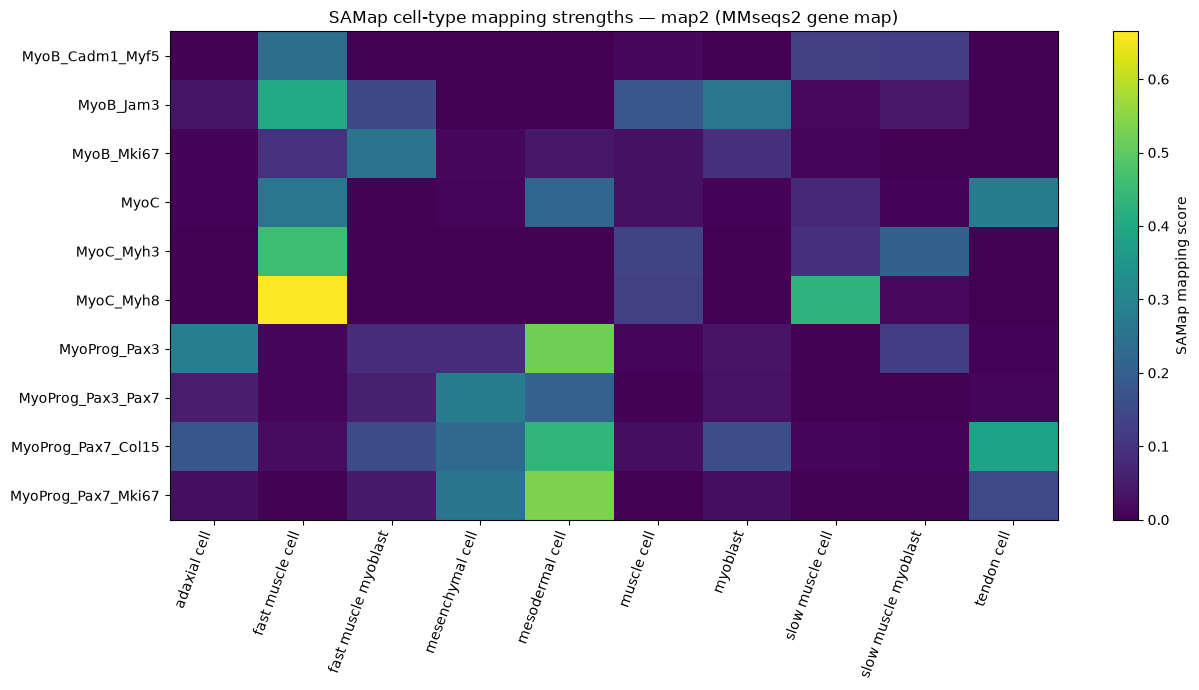

In [4]:
fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(cross.values, aspect='auto', interpolation='nearest', vmin=0)
ax.set_xticks(range(len(dr_names)), [s.removeprefix('dr_') for s in dr_names], rotation=70, ha='right')
ax.set_yticks(range(len(mm_names)), [s.removeprefix('mm_') for s in mm_names])
ax.set_title('SAMap cell-type mapping strengths — map2 (MMseqs2 gene map)')
fig.colorbar(im, ax=ax, label='SAMap mapping score')
fig.tight_layout()
plt.show()

## C. Reciprocal-best matches and low-alignment candidate groups

Reciprocal-best is a **ranking heuristic**, not a mathematical property required for homology. For a lineage with one-to-many relationships, several biologically valid matches can exist; track the entire mapping profile rather than declaring the second-best match wrong. Both `LOW_ALIGNMENT_THRESHOLD` and `STRONG_ALIGNMENT_THRESHOLD` are hypotheses requiring validation against WP2 map1/map2 and repeated subsamples.

In [5]:
def summarize_mapping(cross, low=0.25, strong=0.30):
    rows=[]
    for sp, names, partner in [('mm', cross.index, cross.columns), ('dr', cross.columns, cross.index)]:
        for label in names:
            vals = cross.loc[label] if sp == 'mm' else cross[label]
            ranked = vals.sort_values(ascending=False)
            best, score = str(ranked.index[0]), float(ranked.iloc[0])
            second = float(ranked.iloc[1]) if len(ranked) > 1 else np.nan
            other_best = (cross[best].idxmax() if sp=='mm' else cross.loc[best].idxmax())
            rows.append(dict(species=sp, label=label, best_partner=best, best_score=score,
                             second_score=second, margin=score-second,
                             reciprocal_best=(str(other_best)==label),
                             candidate_weak_alignment=(score < low),
                             candidate_reference=(score >= strong and str(other_best)==label)))
    result=pd.DataFrame(rows)
    result['alignment_percentile_within_species']=result.groupby('species')['best_score'].rank(pct=True)
    result['relative_lowest_quartile']=result['alignment_percentile_within_species']<=0.25
    result['candidate_weak_alignment']=(result['candidate_weak_alignment'] | result['relative_lowest_quartile'])
    return result.sort_values(['species','best_score'])

mapping_summary=summarize_mapping(cross, LOW_ALIGNMENT_THRESHOLD, STRONG_ALIGNMENT_THRESHOLD)
display(mapping_summary)
mapping_summary.to_csv(OUTPUT_DIR / 'map2_type_mapping_summary.csv', index=False)
print('Candidate weak-alignment groups:', mapping_summary.candidate_weak_alignment.sum())
print('Reciprocal strong reference groups:', mapping_summary.candidate_reference.sum())

,species,label,best_partner,best_score,second_score,margin,reciprocal_best,candidate_weak_alignment,candidate_reference,alignment_percentile_within_species,relative_lowest_quartile
15,dr,dr_muscle cell,mm_MyoB_Jam3,0.180948,0.136367,0.044581,False,True,False,0.1,True
18,dr,dr_slow muscle myoblast,mm_MyoC_Myh3,0.205833,0.124212,0.081621,False,True,False,0.2,True
12,dr,dr_fast muscle myoblast,mm_MyoB_Mki67,0.253402,0.153133,0.100269,True,False,False,0.3,False
16,dr,dr_myoblast,mm_MyoB_Jam3,0.261291,0.158377,0.102914,False,False,False,0.4,False
13,dr,dr_mesenchymal cell,mm_MyoProg_Pax3_Pax7,0.283066,0.259280,0.023787,True,False,False,0.5,False
10,dr,dr_adaxial cell,mm_MyoProg_Pax3,0.287606,0.178424,0.109182,False,False,False,0.6,False
19,dr,dr_tendon cell,mm_MyoProg_Pax7_Col15,0.384820,0.281221,0.103600,False,False,False,0.7,False
17,dr,dr_slow muscle cell,mm_MyoC_Myh8,0.431492,0.131941,0.299551,False,False,False,0.8,False
14,dr,dr_mesodermal cell,mm_MyoProg_Pax7_Mki67,0.535181,0.521722,0.013459,True,False,True,0.9,False
11,dr,dr_fast muscle cell,mm_MyoC_Myh8,0.665090,0.458678,0.206413,True,False,True,1.0,False


Candidate weak-alignment groups: 4
Reciprocal strong reference groups: 4


## D. Read GenePairFinder output without treating it as the complete gene map

`GenePair_annot_map2.tsv` is a **wide** table: groups of three columns contain a `dr_gene;mm_gene` pair and two values named `_pval1`, `_pval2` for an aligned cell-type pair. `find_all(align_thr=0.1)` was used in the original notebook; absence of a cell-type-pair column does **not** demonstrate missing homology. Preserve the source p-value fields unchanged; do not interpret them as new measures of homology or rank solely by zero (underflowed) p-values.

In [6]:
def long_gene_pairs(path):
    wide=pd.read_csv(path, sep='\t')
    pieces=[]
    bases=[c for c in wide.columns if not c.endswith(('_pval1','_pval2'))]
    for base in bases:
        if ';' not in base: continue
        v=wide[base]
        sub=pd.DataFrame({'cell_type_pair':base,'gene_pair':v,
                          'pval1':wide.get(base+'_pval1'),
                          'pval2':wide.get(base+'_pval2')})
        sub=sub[sub['gene_pair'].notna() & (sub['gene_pair'].astype(str).str.contains(';',regex=False))].copy()
        sub[['dr_gene','mm_gene']]=sub['gene_pair'].astype(str).str.split(';',n=1,expand=True)
        sub['dr_cell_type'],sub['mm_cell_type']=base.split(';',1)
        sub['source_rank']=np.arange(1,len(sub)+1)
        pieces.append(sub)
    return pd.concat(pieces,ignore_index=True) if pieces else pd.DataFrame()

gene_pairs=long_gene_pairs(MAP2_GENEPAIRS)
print('Gene-pair entries:', len(gene_pairs), '| cell-type pairs:', gene_pairs.cell_type_pair.nunique())
display(gene_pairs.head(10))
gene_pairs.to_csv(OUTPUT_DIR / 'map2_gene_pairs_long.csv',index=False)
print('Gene pairs per cell-type relationship:')
display(gene_pairs.groupby('cell_type_pair').size().sort_values(ascending=False).head(20).rename('n_pairs'))

Gene-pair entries: 20666 | cell-type pairs: 31


,cell_type_pair,gene_pair,pval1,pval2,dr_gene,mm_gene,dr_cell_type,mm_cell_type,source_rank
0,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat3,4.653067e-46,0.000000e+00,dr_pcdh8,mm_Fat3,dr_adaxial cell,mm_MyoProg_Pax3,1
1,dr_adaxial cell;mm_MyoProg_Pax3,dr_si:dkey-112m2.1;mm_Tmem132d,4.455085e-09,0.000000e+00,dr_si:dkey-112m2.1,mm_Tmem132d,dr_adaxial cell,mm_MyoProg_Pax3,2
2,dr_adaxial cell;mm_MyoProg_Pax3,dr_adgrl2a;mm_Adgrl2,1.432558e-138,0.000000e+00,dr_adgrl2a,mm_Adgrl2,dr_adaxial cell,mm_MyoProg_Pax3,3
3,dr_adaxial cell;mm_MyoProg_Pax3,dr_epha4a;mm_Epha7,6.619054e-33,0.000000e+00,dr_epha4a,mm_Epha7,dr_adaxial cell,mm_MyoProg_Pax3,4
4,dr_adaxial cell;mm_MyoProg_Pax3,dr_ntn5;mm_Ntn1,1.217166e-13,0.000000e+00,dr_ntn5,mm_Ntn1,dr_adaxial cell,mm_MyoProg_Pax3,5
5,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat4,4.653067e-46,0.000000e+00,dr_pcdh8,mm_Fat4,dr_adaxial cell,mm_MyoProg_Pax3,6
6,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Pcdh15,4.653067e-46,0.000000e+00,dr_pcdh8,mm_Pcdh15,dr_adaxial cell,mm_MyoProg_Pax3,7
7,dr_adaxial cell;mm_MyoProg_Pax3,dr_sema6bb;mm_Sema3d,6.677751e-14,0.000000e+00,dr_sema6bb,mm_Sema3d,dr_adaxial cell,mm_MyoProg_Pax3,8
8,dr_adaxial cell;mm_MyoProg_Pax3,dr_rxraa;mm_Nr2f2,2.560040e-64,1.958413e-169,dr_rxraa,mm_Nr2f2,dr_adaxial cell,mm_MyoProg_Pax3,9
9,dr_adaxial cell;mm_MyoProg_Pax3,dr_LO016987.1;mm_Epha7,4.571306e-04,0.000000e+00,dr_LO016987.1,mm_Epha7,dr_adaxial cell,mm_MyoProg_Pax3,10


Gene pairs per cell-type relationship:


cell_type_pair
dr_mesodermal cell;mm_MyoProg_Pax3               952
dr_mesodermal cell;mm_MyoProg_Pax7_Col15         942
dr_tendon cell;mm_MyoProg_Pax7_Col15             938
dr_mesodermal cell;mm_MyoProg_Pax7_Mki67         926
dr_mesenchymal cell;mm_MyoProg_Pax3_Pax7         922
dr_mesodermal cell;mm_MyoProg_Pax3_Pax7          920
dr_mesenchymal cell;mm_MyoProg_Pax7_Mki67        899
dr_mesenchymal cell;mm_MyoProg_Pax7_Col15        889
dr_tendon cell;mm_MyoProg_Pax7_Mki67             840
dr_fast muscle myoblast;mm_MyoProg_Pax7_Col15    836
dr_fast muscle myoblast;mm_MyoB_Jam3             812
dr_fast muscle myoblast;mm_MyoB_Mki67            791
dr_mesodermal cell;mm_MyoC                       756
dr_tendon cell;mm_MyoC                           746
dr_adaxial cell;mm_MyoProg_Pax3                  704
dr_adaxial cell;mm_MyoProg_Pax7_Col15            677
dr_muscle cell;mm_MyoB_Jam3                      674
dr_slow muscle myoblast;mm_MyoProg_Pax3          641
dr_myoblast;mm_MyoProg_Pax7_Col

In [7]:
# Candidate groups and their top *reported* gene pairs; these are not species-exclusive markers.
focus_labels=['dr_adaxial cell','dr_slow muscle cell','dr_slow muscle myoblast',
              'dr_fast muscle cell','mm_MyoC_Myh8']
for target in focus_labels:
    sel=gene_pairs[(gene_pairs.dr_cell_type==target)|(gene_pairs.mm_cell_type==target)]
    print('\n',target, '| cell-type relationships:',sel.cell_type_pair.nunique(), '| gene-pair rows:',len(sel))
    if len(sel): display(sel[['cell_type_pair','gene_pair','pval1','pval2','source_rank']].head(12))


 dr_adaxial cell | cell-type relationships: 2 | gene-pair rows: 1381


,cell_type_pair,gene_pair,pval1,pval2,source_rank
0,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat3,4.653067e-46,0.000000e+00,1
1,dr_adaxial cell;mm_MyoProg_Pax3,dr_si:dkey-112m2.1;mm_Tmem132d,4.455085e-09,0.000000e+00,2
2,dr_adaxial cell;mm_MyoProg_Pax3,dr_adgrl2a;mm_Adgrl2,1.432558e-138,0.000000e+00,3
3,dr_adaxial cell;mm_MyoProg_Pax3,dr_epha4a;mm_Epha7,6.619054e-33,0.000000e+00,4
4,dr_adaxial cell;mm_MyoProg_Pax3,dr_ntn5;mm_Ntn1,1.217166e-13,0.000000e+00,5
5,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat4,4.653067e-46,0.000000e+00,6
6,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Pcdh15,4.653067e-46,0.000000e+00,7
7,dr_adaxial cell;mm_MyoProg_Pax3,dr_sema6bb;mm_Sema3d,6.677751e-14,0.000000e+00,8
8,dr_adaxial cell;mm_MyoProg_Pax3,dr_rxraa;mm_Nr2f2,2.560040e-64,1.958413e-169,9
9,dr_adaxial cell;mm_MyoProg_Pax3,dr_LO016987.1;mm_Epha7,4.571306e-04,0.000000e+00,10



 dr_slow muscle cell | cell-type relationships: 2 | gene-pair rows: 1002


,cell_type_pair,gene_pair,pval1,pval2,source_rank
15402,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_clstn1;mm_Clstn2,1.644213e-36,0.000000e+00,1
15403,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_si:dkey-28i19.1;mm_Prdm1,1.750200e-57,0.000000e+00,2
15404,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_glra4a;mm_Gabrb2,2.072971e-162,1.561855e-169,3
15405,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_fgf13a;mm_Fgf6,0.000000e+00,1.392235e-64,4
15406,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_mef2aa;mm_Mef2c,0.000000e+00,0.000000e+00,5
15407,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_fgf13a;mm_Fgf14,0.000000e+00,6.114967e-193,6
15408,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_nectin3b;mm_Nectin3,1.334358e-226,0.000000e+00,7
15409,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_fgf11a;mm_Fgf6,4.268672e-85,1.392235e-64,8
15410,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_myl13;mm_Tnnc1,0.000000e+00,0.000000e+00,9
15411,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_mef2ca;mm_Mef2c,2.041651e-306,0.000000e+00,10



 dr_slow muscle myoblast | cell-type relationships: 3 | gene-pair rows: 1738


,cell_type_pair,gene_pair,pval1,pval2,source_rank
16404,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_prdm1a;mm_Prdm1,8.636490e-32,0.0,1
16405,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_nav2a;mm_Nav2,0.000000e+00,0.0,2
16406,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_epha4b;mm_Epha7,3.872448e-34,0.0,3
16407,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_tspan9a;mm_Tspan9,0.000000e+00,0.0,4
16408,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_pkp4;mm_Ctnnd2,2.166153e-137,0.0,5
16409,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_bcam;mm_Cntn5,3.492823e-76,0.0,6
16410,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_prickle2b;mm_Prickle1,8.057701e-205,0.0,7
16411,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_CR936977.2;mm_Nectin3,1.773786e-107,0.0,8
16412,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_mid2;mm_Trim55,1.279882e-266,0.0,9
16413,dr_slow muscle myoblast;mm_MyoB_Cadm1_Myf5,dr_mef2d;mm_Mef2c,0.000000e+00,0.0,10



 dr_fast muscle cell | cell-type relationships: 5 | gene-pair rows: 1572


,cell_type_pair,gene_pair,pval1,pval2,source_rank
1381,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_palld;mm_Palld,3.616153e-93,0.0,1
1382,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_ptprua;mm_Ptprt,6.362207e-139,0.0,2
1383,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_mef2ca;mm_Mef2c,1.177784e-31,0.0,3
1384,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_mef2cb;mm_Mef2c,4.644306e-286,0.0,4
1385,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_ptprua;mm_Ptprk,6.362207e-139,0.0,5
1386,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_myo16;mm_Myo16,6.082417e-06,0.0,6
1387,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_ctnna2;mm_Ctnna2,0.000000e+00,0.0,7
1388,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_epha3;mm_Epha7,4.450550e-26,0.0,8
1389,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_cacna2d1a;mm_Cacna2d1,0.000000e+00,0.0,9
1390,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_kcnma1a;mm_Kcnma1,0.000000e+00,0.0,10



 mm_MyoC_Myh8 | cell-type relationships: 3 | gene-pair rows: 1396


,cell_type_pair,gene_pair,pval1,pval2,source_rank
2529,dr_fast muscle cell;mm_MyoC_Myh8,dr_myhz1.1__ENSDARG00000067990;mm_Myh8,0.0,0.0,1
2530,dr_fast muscle cell;mm_MyoC_Myh8,dr_tnnt3b;mm_Tnnt3,0.0,0.0,2
2531,dr_fast muscle cell;mm_MyoC_Myh8,dr_myhz1.3;mm_Myh8,0.0,0.0,3
2532,dr_fast muscle cell;mm_MyoC_Myh8,dr_tnnt3a;mm_Tnnt3,0.0,0.0,4
2533,dr_fast muscle cell;mm_MyoC_Myh8,dr_ryr3;mm_Ryr3,0.0,0.0,5
2534,dr_fast muscle cell;mm_MyoC_Myh8,dr_myhz1.2;mm_Myh8,0.0,0.0,6
2535,dr_fast muscle cell;mm_MyoC_Myh8,dr_tnni2a.4;mm_Tnni2,0.0,0.0,7
2536,dr_fast muscle cell;mm_MyoC_Myh8,dr_mylz3;mm_Myl1,0.0,0.0,8
2537,dr_fast muscle cell;mm_MyoC_Myh8,dr_myom2a;mm_Myom2,0.0,0.0,9
2538,dr_fast muscle cell;mm_MyoC_Myh8,dr_mylz3;mm_Tnnc2,0.0,0.0,10


## E. Load/inspect the exported H5AD with Scanpy (read-only source file)

`sc.read_h5ad(path, backed='r')` gives a regular Scanpy `AnnData` handle with HDF5-backed `.X`, reducing unnecessary RAM consumption while metadata and stored embeddings are inspected. Scanpy plotting functions can use metadata in `.obs` and existing coordinates in `.obsm`. **Do not call `sc.pp.neighbors` or `sc.tl.umap` to recreate the SAMap joint atlas**: the original alignment should remain unchanged.

The file may have been downsampled; inspect whether its neighborhood graph corresponds to the downsampled cells. Metadata naming and expression scaling are **not** guaranteed, so the notebook discovers keys and pauses before expression-based modeling.


In [8]:
def choose_map2_h5ad():
    if MAP2_H5AD is not None:
        path=Path(MAP2_H5AD)
        if not path.is_file():
            raise FileNotFoundError(path)
        return path
    candidates=[p for p in DATA_DIR.glob('*.h5ad') if 'map2' in p.name.lower()]
    if len(candidates)==1:
        return candidates[0]
    if len(candidates)>1:
        print('Several map2 H5ADs:', [p.name for p in candidates], '— set MAP2_H5AD explicitly.')
    else:
        print('No map2 H5AD found; mapping-only analyses remain available.')
    return None

h5ad_file=choose_map2_h5ad()
adata=None
if h5ad_file is not None:
    adata=sc.read_h5ad(h5ad_file, backed='r')
    print('Scanpy loaded:', h5ad_file.name, '| cells × features:', adata.shape)
    print('HDF5-backed:', adata.isbacked)
    for name in ('obs','var','obsm','obsp','layers','uns'):
        obj=getattr(adata, name)
        print(name, 'keys:', list(obj.columns)[:60] if name in ('obs','var') else list(obj.keys())[:60])
    print('raw available:', adata.raw is not None)
    for k in adata.obsm.keys():
        v=adata.obsm[k]
        print('obsm', k, 'shape', getattr(v,'shape',None), 'type',type(v).__name__)
    for k in adata.uns.keys():
        val=adata.uns[k]
        print('uns', k,'type',type(val).__name__,'shape',getattr(val,'shape',None))
else:
    print('Skipping H5AD-dependent cells until the files are placed in DATA_DIR.')


Scanpy loaded: samap_mm_dr_map2_20K.h5ad | cells × features: (20000, 77556)
HDF5-backed: True
obs keys: ['mm_donor_id', 'mm_development_stage_ontology_term_id', 'mm_sex_ontology_term_id', 'mm_self_reported_ethnicity_ontology_term_id', 'mm_disease_ontology_term_id', 'mm_tissue_ontology_term_id', 'mm_cell_type_ontology_term_id', 'mm_assay_ontology_term_id', 'mm_suspension_type', 'mm_author_experimental_id', 'mm_author_day', 'mm_author_somite_count', 'mm_author_major_cell_cluster', 'mm_author_cell_type', 'mm_tissue_type', 'mm_cell_type_origin', 'mm_assay', 'mm_disease', 'mm_sex', 'mm_tissue', 'mm_self_reported_ethnicity', 'mm_development_stage', 'mm_leiden_re_0.3', 'mm_leiden_re_0.6', 'mm_leiden_re_0.4', 'mm_leiden_re_1', 'mm_cell_type', 'mm_leiden_clusters', 'dr_projection_group', 'dr_cell_type_long', 'dr_cell_type_broad', 'dr_embryo_ID', 'dr_perturbation', 'dr_target', 'dr_type', 'dr_strain', 'dr_expt', 'dr_cross_batch', 'dr_collection_batch', 'dr_cell_type_ontology_term_id', 'dr_donor_

## F. Harmonize species and cell-type labels in `.obs`

The source SAMap notebook uses `species`, `mm_cell_type` and `dr_cell_type`. Inspect the actual columns before proceeding. We infer labels into a separate `cell_info` table and add plotting-only metadata prefixed `wp3_` to the **in-memory** Scanpy object. The source H5AD remains unchanged (`backed='r'`, no `write_h5ad`).


In [9]:
cell_info=None
if adata is not None:
    obs=adata.obs.copy()
    species_col=next((x for x in ('species','Species','organism') if x in obs),None)
    if species_col is None:
        print('No recognizable species label in .obs. Set species mapping manually before novelty modeling.')
    else:
        raw_species=obs[species_col].astype('string').str.lower().str.strip()
        species=np.select([raw_species.isin(['mm','mouse','mus musculus']),
                           raw_species.isin(['dr','zebrafish','danio rerio'])], ['mm','dr'],default='other')
        labels=[]
        for ix, s in enumerate(species):
            if s=='mm' and 'mm_cell_type' in obs:
                value=obs['mm_cell_type'].iloc[ix]
            elif s=='dr' and 'dr_cell_type' in obs:
                value=obs['dr_cell_type'].iloc[ix]
            elif 'cell_type' in obs:
                value=obs['cell_type'].iloc[ix]
            else: value=np.nan
            val=str(value) if pd.notna(value) and str(value).lower() not in ['nan','none','-1'] else ''
            labels.append(val if val.startswith(('mm_','dr_')) else (s+'_'+val if val and s in ('mm','dr') else ''))
        cell_info=pd.DataFrame({'cell_id':obs.index.astype(str),'species':species,'label':labels})
        lookup=mapping_summary.set_index('label')
        for col in ['best_score','best_partner','reciprocal_best','candidate_reference','candidate_weak_alignment']:
            cell_info[col]=cell_info['label'].map(lookup[col])
        print('Species counts:'); display(cell_info.species.value_counts())
        print('Unmatched / missing mapping labels:',int(cell_info.best_score.isna().sum()),'/',len(cell_info))
        display(cell_info.groupby(['species','label'],dropna=False).size().rename('cells').reset_index().head(35))
        if cell_info.best_score.isna().mean()>0.10:
            warnings.warn('Many cells do not match the mapping table; verify label naming or map version.')

Species counts:


species
mm    15161
dr     4839
Name: count, dtype: int64

Unmatched / missing mapping labels: 0 / 20000


,species,label,cells
0,dr,dr_adaxial cell,9
1,dr,dr_fast muscle cell,2767
2,dr,dr_fast muscle myoblast,60
3,dr,dr_mesenchymal cell,85
4,dr,dr_mesodermal cell,586
5,dr,dr_muscle cell,162
6,dr,dr_myoblast,51
7,dr,dr_slow muscle cell,912
8,dr,dr_slow muscle myoblast,124
9,dr,dr_tendon cell,83


## G. Visualization and optional cross-species graph-neighbor diagnostic

If `X_umap` exists, use it for visualization only. When a joint `connectivities` graph exists, estimate the fraction of weight connecting each cell to the other species. This is a **graph-mixing diagnostic** and only meaningful after verifying the stored graph is the SAMap cross-species graph; do not equate it with homology.

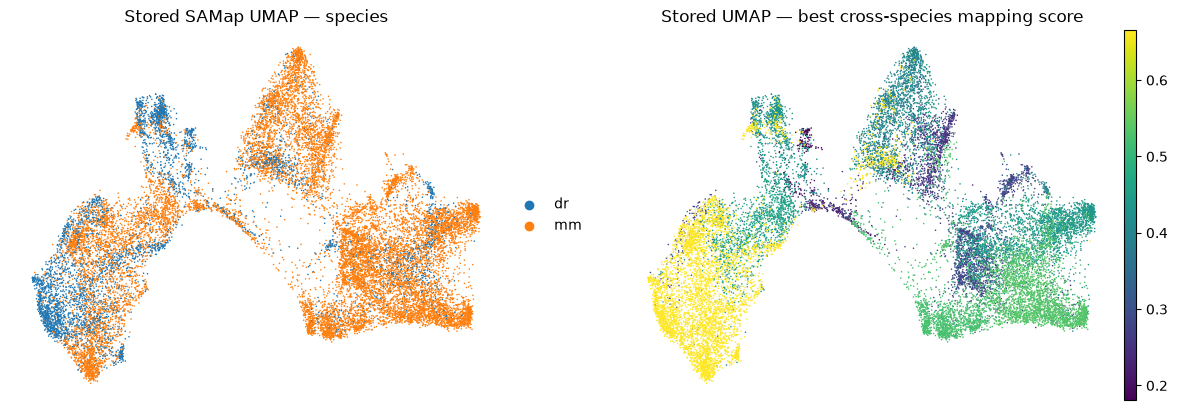

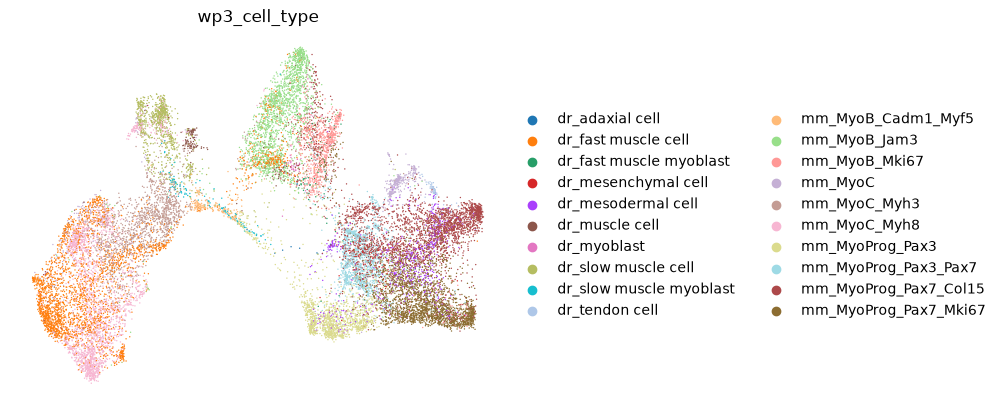

No precomputed QC columns in .obs. Not calculating them from an unknown SAMap .X.


,cross_species_graph_fraction
label,
dr_myoblast,0.452661
mm_MyoProg_Pax7_Mki67,0.511871
dr_muscle cell,0.515303
mm_MyoProg_Pax3_Pax7,0.519485
mm_MyoB_Mki67,0.527670
dr_fast muscle myoblast,0.530055
mm_MyoC_Myh3,0.558667
dr_adaxial cell,0.561202
mm_MyoProg_Pax7_Col15,0.570512


In [10]:
if adata is not None and cell_info is not None:
    # Scanpy plots the ALREADY-STORED joint SAMap UMAP; no neighbor graph or UMAP is recomputed.
    adata.obs['wp3_species'] = pd.Categorical(cell_info['species'].to_numpy())
    adata.obs['wp3_best_samap_score'] = cell_info['best_score'].to_numpy(dtype=float)
    adata.obs['wp3_cell_type'] = pd.Categorical(cell_info['label'].to_numpy())
    if 'X_umap' in adata.obsm:
        if adata.obsm['X_umap'].shape[1] >= 2:
            sc.pl.umap(
                adata,
                color=['wp3_species', 'wp3_best_samap_score'],
                title=['Stored SAMap UMAP — species', 'Stored UMAP — best cross-species mapping score'],
                ncols=2, size=5, frameon=False, show=False,
            )
            plt.show()
            # An additional categorical view is useful for tracking the suspected
            # adaxial and slow/fast muscle populations within the stored manifold.
            sc.pl.umap(adata, color='wp3_cell_type', size=4,
                       legend_loc='right margin', frameon=False, show=False)
            plt.show()
    else:
        print('No X_umap in obsm: Scanpy UMAP plotting skipped (no coordinates recomputed).')

    # Optional read-only scanpy QC plots, but ONLY for QC statistics already in .obs.
    qc_fields=[k for k in ('n_genes_by_counts','total_counts','pct_counts_mt') if k in adata.obs.columns]
    if qc_fields:
        try:
            sc.pl.violin(adata, keys=qc_fields, groupby='wp3_species',
                         stripplot=False, multi_panel=True, show=False)
            plt.show()
        except Exception as exc:
            print('Scanpy QC plot unavailable:', type(exc).__name__, str(exc)[:180])
    else:
        print('No precomputed QC columns in .obs. Not calculating them from an unknown SAMap .X.')

    if 'connectivities' in adata.obsp:
        try:
            G=adata.obsp['connectivities']
            G=G.tocsr() if sp.issparse(G) else sp.csr_matrix(G)
            if G.shape[0]==len(cell_info):
                ii=np.repeat(np.arange(G.shape[0]),np.diff(G.indptr))
                si=cell_info.species.to_numpy()
                all_weight=np.bincount(ii,weights=G.data,minlength=G.shape[0])
                cross_weight=np.bincount(ii,weights=G.data*(si[ii]!=si[G.indices]),minlength=G.shape[0])
                cell_info['cross_species_graph_fraction']=np.divide(cross_weight,all_weight,
                    out=np.full_like(all_weight,np.nan,dtype=float),where=all_weight>0)
                display(cell_info.groupby('label').cross_species_graph_fraction.mean().sort_values().to_frame().head(20))
        except Exception as exc:
            print('Graph diagnostic skipped:',type(exc).__name__,str(exc)[:200])


## H. Novelty/outlier detection on a suitable existing representation

- **Isolation Forest:** global anomaly *within each species*; higher `-score_samples` is more unusual.
- **LOF:** unusual density relative to *within-species neighbors*; use `novelty=False` and `negative_outlier_factor_` on fitted cells.
- **One-Class SVM:** train a reference distribution using cell types with **strong, reciprocal SAMap matches**. Use a restricted reference sample to keep its quadratic complexity manageable. Its output is a *decision score*, not a likelihood.

**Do not** run this blindly on a 2D UMAP. When available, a derived SVD of the *stored* joint connectivity graph is a plausible exploratory substitute, but is not the original SAMap PC manifold. A randomly sampled H5AD is not guaranteed to retain the full joint graph, high-dimensional manifold, or original cell-type frequencies. Score ranks are calculated *within species* and are not calibrated probabilities. Training on SAMap-positive mappings is partly circular; validation needs independent biological labels or WP2 perturbations.

In [11]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

embedding=None; embedding_key=None
if adata is not None and cell_info is not None:
    preferred=['X_pca','X_samap','X_sam','X_sam_pca','X_integrated']
    available=list(adata.obsm.keys())
    for key in preferred + [k for k in available if k not in preferred and k!='X_umap']:
        if key in available and len(getattr(adata.obsm[key],'shape',()))==2 and adata.obsm[key].shape[1]>=10:
            embedding_key=key; break
    if embedding_key is None and ALLOW_GRAPH_SVD_EMBEDDING and 'connectivities' in adata.obsp:
        from sklearn.decomposition import TruncatedSVD
        G=adata.obsp['connectivities']
        G=G.tocsr() if sp.issparse(G) else sp.csr_matrix(G)
        if G.shape==(adata.n_obs,adata.n_obs) and G.nnz>0 and adata.n_obs>50:
            ncomp=min(30,adata.n_obs-2)
            embedding=TruncatedSVD(n_components=ncomp,random_state=SEED).fit_transform(G).astype(np.float32)
            embedding_key='graph_SVD_derived_from_stored_connectivities'
            warnings.warn('Using derived spectral coordinates of the *stored* graph, not original SAMap PC coordinates; verify provenance of connectivities.')
    if embedding_key is None and ALLOW_UMAP_FOR_NOVELTY and 'X_umap' in available:
        embedding_key='X_umap'
        warnings.warn('Using UMAP distances for anomaly modeling: illustrative only; results are not reliable novelty evidence.')
    if embedding_key is None:
        print('No verified high-dimensional existing embedding. Novelty algorithms skipped. Available obsm:', available)
    else:
        if embedding is None:
            value=adata.obsm[embedding_key]
            embedding=value.toarray().astype(np.float32) if sp.issparse(value) else np.asarray(value,dtype=np.float32)
        if not np.isfinite(embedding).all():
            warnings.warn('Non-finite embedding values; novelty skipped until corrected.')
            embedding=None
        else: print('Novelty embedding:',embedding_key,embedding.shape)

Novelty embedding: graph_SVD_derived_from_stored_connectivities (20000, 30)


/tmp/ipykernel_148327/771975640.py:21: UserWarning: Using derived spectral coordinates of the *stored* graph, not original SAMap PC coordinates; verify provenance of connectivities.
  warnings.warn('Using derived spectral coordinates of the *stored* graph, not original SAMap PC coordinates; verify provenance of connectivities.')


In [12]:
novelty_results=None
if embedding is not None and cell_info is not None:
    # Downsample stratified by annotation to reduce distortion of rare groups.
    group_indices=list(cell_info.groupby(['species','label'],sort=True).indices.values())
    total=len(cell_info)
    quota=max(15,int(MAX_CELLS_FOR_NOVELTY/max(1,len(group_indices))))
    ix_list=[rng.choice(ix,size=min(len(ix),quota),replace=False) for ix in group_indices if len(ix)]
    idx=np.unique(np.concatenate(ix_list))
    if len(idx)>MAX_CELLS_FOR_NOVELTY:
        idx=np.sort(rng.choice(idx,size=MAX_CELLS_FOR_NOVELTY,replace=False))
    sub=cell_info.iloc[idx].copy().reset_index(drop=True)
    E=embedding[idx]
    sub['isoforest_anomaly']=np.nan
    sub['lof_anomaly']=np.nan
    sub['ocsvm_anomaly']=np.nan
    for sid in ('mm','dr'):
        loc=np.flatnonzero(sub.species.to_numpy()==sid)
        if len(loc)<35:continue
        Z=StandardScaler().fit_transform(E[loc])
        iso=IsolationForest(n_estimators=150,random_state=SEED,max_samples='auto',n_jobs=-1)
        iso.fit(Z);sub.loc[loc,'isoforest_anomaly']=-iso.score_samples(Z)
        lof=LocalOutlierFactor(n_neighbors=min(30,len(loc)-1),contamination='auto',novelty=False,n_jobs=-1)
        lof.fit(Z);sub.loc[loc,'lof_anomaly']=-lof.negative_outlier_factor_
    ref_idx=np.flatnonzero(sub.candidate_reference.fillna(False).to_numpy(dtype=bool))
    if len(ref_idx)>=100 and len(set(sub.species.iloc[ref_idx]))==2:
        # Balance reference species so the model does not merely learn species abundance.
        per_species=[]
        for sid in ('mm','dr'):
            tmp=ref_idx[sub.species.iloc[ref_idx].to_numpy()==sid]
            per_species.append(rng.choice(tmp,size=min(len(tmp),MAX_OCSVM_REFERENCE//2),replace=False))
        train_ref=np.concatenate(per_species)
        scaler=StandardScaler().fit(E[train_ref]); Zref=scaler.transform(E[train_ref]); Zall=scaler.transform(E)
        model=OneClassSVM(kernel='rbf',nu=0.05,gamma='scale',cache_size=300)
        model.fit(Zref)
        sub['ocsvm_anomaly']=-model.decision_function(Zall)
        sub['ocsvm_was_training_cell']=False
        sub.loc[train_ref,'ocsvm_was_training_cell']=True
        print('OCSVM reference cell count:',len(train_ref),'— in-sample reference scores may be optimistic.')
    else:
        print('Too few strong reciprocal reference cells for OCSVM; skipping OCSVM.')
    cols=['isoforest_anomaly','lof_anomaly','ocsvm_anomaly']
    for col in cols:
        sub[col+'_percentile']=sub.groupby('species')[col].rank(pct=True)
    rank_cols=[x+'_percentile' for x in cols]
    sub['mean_anomaly_percentile']=sub[rank_cols].mean(axis=1)
    novelty_results=sub
    display(sub.groupby(['species','label']).agg(n=('cell_id','size'),
        median_anomaly=('mean_anomaly_percentile','median'),
        best_alignment=('best_score','first')).sort_values('median_anomaly',ascending=False).head(20))
    sub.to_csv(OUTPUT_DIR/'map2_cell_novelty_scores.csv',index=False)
else:
    print('Novelty section skipped: no H5AD/metadata/high-dimensional embedding available.')

OCSVM reference cell count: 2500 — in-sample reference scores may be optimistic.


n  median_anomaly  best_alignment
species label                                                       
dr      dr_tendon cell            83        0.612594        0.384820
mm      mm_MyoB_Jam3             750        0.605583        0.403372
        mm_MyoProg_Pax3          750        0.593600        0.521722
dr      dr_fast muscle myoblast   60        0.583584        0.253402
        dr_adaxial cell            9        0.561905        0.287606
mm      mm_MyoProg_Pax7_Col15    750        0.554877        0.438527
        mm_MyoB_Mki67            750        0.535787        0.253402
        mm_MyoProg_Pax3_Pax7     750        0.528148        0.283066
        mm_MyoProg_Pax7_Mki67    750        0.520460        0.535181
        mm_MyoC_Myh8             750        0.506429        0.665090
dr      dr_slow muscle cell      750        0.503070        0.431492
        dr_mesodermal cell       586        0.499029        0.535181
        dr_fast muscle cell      750        0.478916        0.665090
        dr_mesenchymal cell       85        0.465163        0.283066
        dr_muscle cell           162        0.453759        0.180948
mm      mm_MyoC                  531        0.452466        0.281221
        mm_MyoB_Cadm1_Myf5       222        0.438102        0.241432
dr      dr_slow muscle myoblast  124        0.435777        0.205833
mm      mm_MyoC_Myh3             750        0.403154        0.458678
dr      dr_myoblast               51        0.282268        0.261291

## I. Compare *group-level* novelty rankings with SAMap confidence

Never compare Isolation Forest, LOF and OCSVM raw scales as if they were equal probabilities. Aggregate **within-species percentile ranks** and inspect exceptions: low alignment but ordinary local density, or strong alignment but high local novelty. Both patterns may expose confounding or annotation mismatches. A candidate with strong independent evidence and reproducible discriminative genes merits follow-up, not a definitive non-homology label.

,species,label,cells,best_alignment,reciprocal_best,mean_anomaly,median_anomaly,iso,lof,ocsvm
5,dr,dr_muscle cell,162,0.180948,False,0.459247,0.453759,0.319435,0.575802,0.482504
8,dr,dr_slow muscle myoblast,124,0.205833,False,0.435182,0.435777,0.334508,0.571632,0.399406
10,mm,mm_MyoB_Cadm1_Myf5,222,0.241432,False,0.437425,0.438102,0.401235,0.418397,0.492644
2,dr,dr_fast muscle myoblast,60,0.253402,True,0.559095,0.583584,0.513139,0.651241,0.512904
12,mm,mm_MyoB_Mki67,750,0.253402,True,0.506385,0.535787,0.489553,0.451377,0.578226
6,dr,dr_myoblast,51,0.261291,False,0.456858,0.282268,0.408378,0.492422,0.469774
13,mm,mm_MyoC,531,0.281221,False,0.460646,0.452466,0.471668,0.530916,0.379355
17,mm,mm_MyoProg_Pax3_Pax7,750,0.283066,True,0.509614,0.528148,0.564440,0.449914,0.514488
3,dr,dr_mesenchymal cell,85,0.283066,True,0.498167,0.465163,0.554153,0.535555,0.404792
0,dr,dr_adaxial cell,9,0.287606,False,0.526399,0.561905,0.407790,0.763826,0.407581


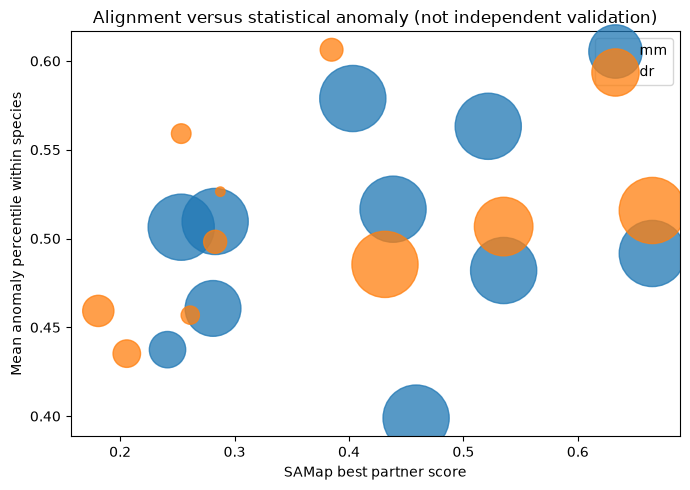

In [13]:
if novelty_results is not None:
    type_results=novelty_results.groupby(['species','label'],as_index=False).agg(
        cells=('cell_id','size'),best_alignment=('best_score','first'),
        reciprocal_best=('reciprocal_best','first'),
        mean_anomaly=('mean_anomaly_percentile','mean'),
        median_anomaly=('mean_anomaly_percentile','median'),
        iso=('isoforest_anomaly_percentile','mean'),
        lof=('lof_anomaly_percentile','mean'),
        ocsvm=('ocsvm_anomaly_percentile','mean'))
    display(type_results.sort_values(['best_alignment','mean_anomaly'],ascending=[True,False]))
    type_results.to_csv(OUTPUT_DIR/'map2_method_comparison_by_cell_type.csv',index=False)
    fig,ax=plt.subplots(figsize=(7,5))
    for sid in ['mm','dr']:
        z=type_results[type_results.species==sid]
        ax.scatter(z.best_alignment,z.mean_anomaly,s=20+3*z.cells,alpha=.75,label=sid)
    ax.set(xlabel='SAMap best partner score',ylabel='Mean anomaly percentile within species',
           title='Alignment versus statistical anomaly (not independent validation)')
    ax.legend();plt.tight_layout();plt.show()

## J. Optional expression-first gene signatures

**Scanpy marker screening** (`sc.tl.rank_genes_groups`) can first identify genes enriched in a candidate cell type relative to other annotated types **within the same species**, using the Wilcoxon rank-sum test. It is an efficient, interpretable exploratory complement to the existing **ElasticNet** one-vs-rest classifiers. Both use expression, unlike the manifold-first anomaly methods.

**Both are optional and OFF initially:** The combined SAMap AnnData might contain transformed expression or structurally missing features. Inspect `.X`, `.layers`, `.var`, and species prefixes. Do not interpret a classifier or a marker screen as evidence of evolutionary gene novelty without paralog/orthology and developmental validation. For Scanpy marker screening, explicitly set `EXPRESSION_MATRIX_STATE` to either `'counts'` or `'log1p_normalized'` after verification; only in the counts case is `sc.pp.normalize_total` / `sc.pp.log1p` performed on a **small species-only in-memory subset**, never on the original SAMap data.

The ElasticNet section below follows the logic of Brito et al. (2025): separate *within-species* one-vs-rest cell-type classifiers rather than a simplistic cross-species classifier.


In [14]:
if adata is not None:
    print('X shape:',adata.shape,'X dtype:',getattr(adata.X,'dtype','unknown'))
    print('layers:',list(adata.layers.keys()),'raw:',adata.raw is not None)
    print('var_names sample:',list(adata.var_names[:15]))
    if adata.n_obs:
        sample_rows=np.sort(rng.choice(adata.n_obs,size=min(15,adata.n_obs),replace=False))
        chunk=adata[sample_rows,:min(250,adata.n_vars)].X
        values=chunk.data if sp.issparse(chunk) else np.asarray(chunk).ravel()
        print('Sample matrix values:',pd.Series(values).describe(percentiles=[.5,.9,.99]).to_dict() if len(values) else {})

X shape: (20000, 77556) X dtype: float32
layers: ['X_disp'] raw: False
var_names sample: ['mm_4933401J01Rik', 'mm_Gm26206', 'mm_Xkr4', 'mm_Gm18956', 'mm_Gm37180', 'mm_Gm37363', 'mm_Gm37686', 'mm_Gm1992', 'mm_Gm37329', 'mm_Gm7341', 'mm_Gm38148', 'mm_Gm19938', 'mm_Gm10568', 'mm_Gm38385', 'mm_Gm27396']
Sample matrix values: {'count': 59.0, 'mean': 1.6196565628051758, 'std': 0.42628759145736694, 'min': 1.0338884592056274, '50%': 1.4720784425735474, '90%': 2.229852247238159, '99%': 2.520216326713562, 'max': 2.528140068054199}


### J1. Scanpy's optional within-species marker discovery

If enabled, this section creates a *temporary* species-specific AnnData subset and runs `sc.tl.rank_genes_groups(method='wilcoxon')`. It is deliberately constrained to species-prefixed features by default: if the joint SAMap `.var_names` cannot be safely attributed to one species, it **skips** instead of interpreting cross-species structural zeros as specific expression. Verify the expression matrix state first.


In [15]:
scanpy_markers=[]
if RUN_SCANPY_MARKERS:
    if adata is None or cell_info is None:
        print('Scanpy marker analysis skipped: H5AD and resolved cell metadata are required.')
    elif EXPRESSION_MATRIX_STATE not in ('counts','log1p_normalized'):
        raise ValueError("Before enabling Scanpy markers, set EXPRESSION_MATRIX_STATE to 'counts' or 'log1p_normalized' based on verified provenance.")
    else:
        targets=['dr_adaxial cell','dr_slow muscle cell','dr_slow muscle myoblast',
                 'dr_fast muscle cell','mm_MyoC_Myh8','mm_MyoProg_Pax3']
        feature_names=np.asarray(adata.var_names.astype(str))
        for sid in ('mm','dr'):
            per_species=np.flatnonzero((cell_info['species']==sid).to_numpy() &
                                       (cell_info['label']!='').to_numpy())
            if len(per_species)<80:
                print('SKIP',sid,'too few annotated cells'); continue
            gene_idx=np.flatnonzero(np.char.startswith(feature_names.astype(str), sid+'_'))
            if len(gene_idx)<100:
                if not ALLOW_UNPREFIXED_FEATURES:
                    print('SKIP',sid, 'cannot verify species-specific feature namespace. Inspect .var_names and set ALLOW_UNPREFIXED_FEATURES only if valid.')
                    continue
                gene_idx=np.arange(adata.n_vars)
            # A capped, seeded subset controls memory. Original AnnData remains read-only.
            if len(per_species)>MAX_CELLS_FOR_SCANPY_MARKERS:
                per_species=np.sort(rng.choice(per_species, MAX_CELLS_FOR_SCANPY_MARKERS, replace=False))
            tmp=adata[per_species,gene_idx].to_memory()
            if EXPRESSION_LAYER is not None:
                if EXPRESSION_LAYER not in tmp.layers:
                    raise KeyError(f'Missing expression layer: {EXPRESSION_LAYER}')
                tmp.X=tmp.layers[EXPRESSION_LAYER].copy()
            tmp.obs['wp3_cell_type']=pd.Categorical(cell_info['label'].iloc[per_species].to_numpy())
            if EXPRESSION_MATRIX_STATE == 'counts':
                sc.pp.normalize_total(tmp, target_sum=1e4)
                sc.pp.log1p(tmp)
            else:
                print('Using verified pre-existing log1p-normalized expression for',sid)
            sc.pp.filter_genes(tmp, min_cells=5)
            if tmp.n_vars<20:
                print('SKIP',sid,'too few expressed features'); continue
            for target in [t for t in targets if t.startswith(sid+'_')]:
                npos=int((tmp.obs['wp3_cell_type']==target).sum())
                if npos<30 or tmp.n_obs-npos<30:
                    print('SKIP',target,'insufficient positive / reference cells'); continue
                key='wp3_markers_'+sid
                sc.tl.rank_genes_groups(tmp, groupby='wp3_cell_type', groups=[target],
                                        reference='rest', method='wilcoxon', use_raw=False,
                                        key_added=key)
                result=sc.get.rank_genes_groups_df(tmp, group=target, key=key)
                result.insert(0,'cell_type',target)
                result.insert(1,'species',sid)
                display(result.head(12))
                scanpy_markers.append(result)
            del tmp
        if scanpy_markers:
            pd.concat(scanpy_markers,ignore_index=True).to_csv(
                OUTPUT_DIR/'map2_scanpy_within_species_markers.csv', index=False)
else:
    print('Scanpy marker analysis is OFF until the source expression scale and feature namespace are verified.')


Scanpy marker analysis is OFF until the source expression scale and feature namespace are verified.


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score

expression_signatures=[]
if RUN_EXPRESSION_MODELS:
    if adata is None or cell_info is None:
        raise RuntimeError('Expression models require an available H5AD with matching metadata.')
    if EXPRESSION_MATRIX_STATE not in ('counts', 'log1p_normalized'):
        raise ValueError('Set EXPRESSION_MATRIX_STATE to verified counts or log1p_normalized before enabling expression models.')
    # A within-species one-vs-rest model of cell identity (Brito et al. style),
    # not a species classifier. Never infer counts from the magnitude of .X.
    targets=['dr_adaxial cell','dr_slow muscle cell','dr_fast muscle cell',
             'mm_MyoC_Myh8','mm_MyoProg_Pax3']
    feature_names=np.asarray(adata.var_names.astype(str))
    for target in targets:
        sid=target.split('_',1)[0]
        pos=np.flatnonzero((cell_info.label==target).to_numpy())
        neg=np.flatnonzero(((cell_info.species==sid)&(cell_info.label!=target)&
                            (cell_info.label!='')).to_numpy())
        if len(pos)<40 or len(neg)<40:
            print('SKIP',target,'insufficient positive or negative cells');continue
        max_each=min(550,len(pos),len(neg))
        rows=np.sort(np.r_[rng.choice(pos,max_each,replace=False),
                           rng.choice(neg,max_each,replace=False)])

        species_gene_mask=np.fromiter((g.startswith(sid+'_') for g in feature_names),
                                      dtype=bool,count=len(feature_names))
        if species_gene_mask.sum() < 100 and not ALLOW_UNPREFIXED_FEATURES:
            print('SKIP',target,'species-specific gene namespace not verified; inspect .var_names')
            continue
        genes=np.flatnonzero(species_gene_mask) if species_gene_mask.sum()>=100 else np.arange(adata.n_vars)
        # Only a small subset is read into memory. The original H5AD remains backed/read-only.
        tmp=adata[rows,genes].to_memory()
        if EXPRESSION_LAYER is not None:
            if EXPRESSION_LAYER not in tmp.layers:
                raise KeyError(f'Missing expression layer: {EXPRESSION_LAYER}')
            tmp.X=tmp.layers[EXPRESSION_LAYER].copy()
        if EXPRESSION_MATRIX_STATE=='counts':
            # Scanpy handles the normalization of this temporary analysis copy.
            sc.pp.normalize_total(tmp,target_sum=1e4)
            sc.pp.log1p(tmp)
        X=tmp.X
        if sp.issparse(X):
            X=X.tocsr().astype(np.float32)
            present=np.asarray((X>0).sum(axis=0)).ravel()
            minimum=float(min(0, X.data.min())) if X.nnz else 0.0
        else:
            X=np.asarray(X,dtype=np.float32)
            present=(X>0).sum(axis=0)
            minimum=float(X.min()) if X.size else 0.0
        if minimum < -1e-8:
            raise ValueError('Negative expression values detected: verify .X/layer provenance.')
        keep=present>=5
        X=X[:,keep]
        names=np.asarray(tmp.var_names.astype(str))[keep]
        if len(names)<10:
            print('SKIP',target,'too few expressed features');continue
        # Reduce model size using variance estimated on the current (normalized) scale.
        if X.shape[1]>5000:
            mean=np.asarray(X.mean(axis=0)).ravel()
            second=np.asarray(X.power(2).mean(axis=0)).ravel() if sp.issparse(X) else (X**2).mean(axis=0)
            var=np.maximum(0,second-mean**2)
            inds=np.argsort(var)[-5000:]
            X=X[:,inds]; names=names[inds]
        y=(cell_info.label.iloc[rows].to_numpy()==target).astype(int)
        itrain,itest=train_test_split(np.arange(len(y)),test_size=.25,
                                     stratify=y,random_state=SEED)
        scaler=StandardScaler(with_mean=not sp.issparse(X))
        Ztrain=scaler.fit_transform(X[itrain]); Ztest=scaler.transform(X[itest])
        model=LogisticRegression(penalty='elasticnet',solver='saga',l1_ratio=.5,
                                 C=.25,class_weight='balanced',max_iter=2500,
                                 random_state=SEED,n_jobs=1)
        with warnings.catch_warnings(record=True) as captured:
            model.fit(Ztrain,y[itrain])
            if captured:
                print('Model warnings:',[str(c.message)[:130] for c in captured[:2]])
        prob=model.predict_proba(Ztest)[:,1]
        print('Performance',target,'balanced accuracy',
              round(balanced_accuracy_score(y[itest],prob>=.5),3),
              'ROC AUC',round(roc_auc_score(y[itest],prob),3),
              'average precision',round(average_precision_score(y[itest],prob),3))
        coef=model.coef_.ravel()
        sig=pd.DataFrame({'cell_type':target,'gene':names,'coef':coef,
                          'abs_coef':np.abs(coef),'positive_signature':coef>0})
        sig=sig[sig.coef!=0].sort_values('coef',ascending=False)
        display(sig.head(15))
        expression_signatures.append(sig)
        del tmp
    if expression_signatures:
        pd.concat(expression_signatures,ignore_index=True).to_csv(
            OUTPUT_DIR/'map2_elasticnet_signatures.csv',index=False)
else:
    print('Expression modeling is OFF until data provenance and matrix scale are verified.')


Expression modeling is OFF until data provenance and matrix scale are verified.


## K. Interpretation, cross-method benchmark, and export

### Minimum evidence required before calling a lineage-specific candidate

1. **Mapping evidence:** low/ambiguous SAMap mapping **and** availability of comparable developmental stages and cell populations; inspect all cross-species partners and map1/map2 sensitivity.
2. **Anomaly evidence:** coherent subset rather than isolated QC failures, and consistency of within-species anomaly ranks across methods and random subsamples.
3. **Expression evidence:** reproducible discriminative markers derived from biologically valid expression matrices, not structural zeros caused by species-specific feature namespaces; examine paralogs/gene families.
4. **Developmental validation:** verify adaxial, slow-/fast-fibre and progenitor stage relationships using external developmental ontogeny; distinguish convergent function and developmental systems drift.
5. **Replicability:** repeat on different 20k subsamples, the full SAMap object or source H5ADs when computationally feasible, and different WP2 gene maps. **Do not rerun SAMap for this notebook.**

### Recommended output vocabulary

`robustly_mapped`, `weakly_mapped_candidate`, `discordant_across_maps`, `locally_anomalous`, `species_enriched_signature` rather than `homolog`/`nonhomolog` assertions.

In [17]:
versions={}
for package in ['scanpy','numpy','pandas','scipy','scikit-learn','anndata','matplotlib']:
    try:versions[package]=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError: versions[package]=None
meta={'seed':SEED, 'data_dir':str(DATA_DIR.resolve()), 'map2_mapping':str(MAP2_MAPPING),
      'map2_h5ad':str(h5ad_file) if h5ad_file else None, 'embedding':embedding_key,
      'low_alignment_threshold':LOW_ALIGNMENT_THRESHOLD,
      'strong_alignment_threshold':STRONG_ALIGNMENT_THRESHOLD,
      'max_cells_for_novelty':MAX_CELLS_FOR_NOVELTY,
      'allow_graph_svd_embedding':ALLOW_GRAPH_SVD_EMBEDDING,
      'allow_umap_for_novelty':ALLOW_UMAP_FOR_NOVELTY,
      'run_scanpy_markers':RUN_SCANPY_MARKERS,
      'expression_matrix_state':EXPRESSION_MATRIX_STATE,
      'run_expression_models':RUN_EXPRESSION_MODELS,'software_versions':versions}
(OUTPUT_DIR/'wp3_run_metadata.json').write_text(json.dumps(meta,indent=2))
print('Saved CSVs and provenance in:',OUTPUT_DIR.resolve())
print('Outputs:',[p.name for p in sorted(OUTPUT_DIR.glob('*'))])
if adata is not None and getattr(adata,'isbacked',False):
    adata.file.close()


Saved CSVs and provenance in: /home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026/wp3_results
Outputs: ['map2_cell_novelty_scores.csv', 'map2_gene_pairs_long.csv', 'map2_method_comparison_by_cell_type.csv', 'map2_type_mapping_summary.csv', 'wp3_run_metadata.json']
